In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("/Users/lucielopez/Desktop/stuff/IRONHACK/LABS/W5/amz_uk_price_prediction_dataset.csv")
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [3]:
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [5]:
# PART 1 : Understanding Product Categories
# 1

category_counts = df["category"].value_counts()
category_counts

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [10]:
category_freq = df['category'].value_counts().reset_index()
category_freq.columns = ['Category', 'Frequency']
print("Top 5 Product Categories :")
print(category_freq.head(5))

Top 5 Product Categories :
                                 Category  Frequency
0                       Sports & Outdoors     836265
1                                  Beauty      19312
2  Handmade Clothing, Shoes & Accessories      19229
3                             Bath & Body      19092
4                          Birthday Gifts      18978


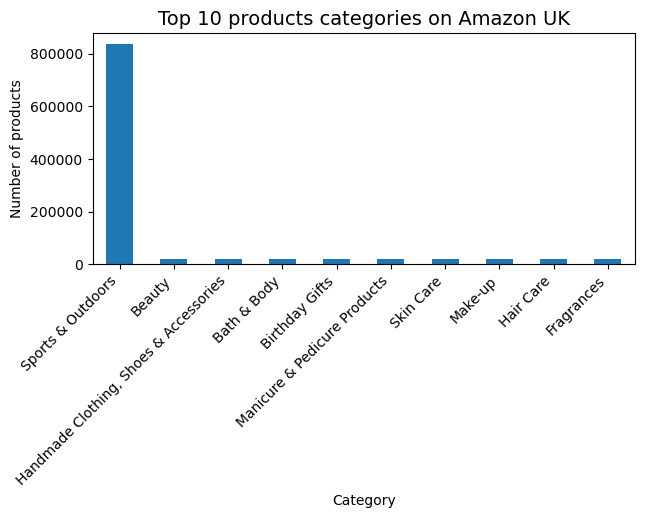

In [17]:
#2 Visualizations

import matplotlib.pyplot as plt

top10 = category_counts.head(10)

plt.figure(figsize=(7,3))
top10.plot(kind="bar")
plt.title("Top 10 products categories on Amazon UK", fontsize=14)
plt.xlabel("Category")
plt.ylabel("Number of products")
plt.xticks(rotation=45, ha="right") 
plt.show()

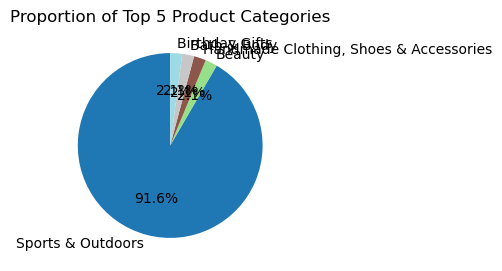

In [19]:
top5 = category_counts.head(5)

plt.figure(figsize=(3,3))
top5.plot(kind='pie', autopct='%1.1f%%', startangle=90, cmap="tab20")
plt.title("Proportion of Top 5 Product Categories")
plt.ylabel("") 
plt.show()

In [ ]:
# Does any category dominate the listings?
# The Sports & Outdoors dominate all the categories so far 

In [22]:
# PART 2 : Delving into Product Pricing
# 1

mean_price = df['price'].mean()

median_price = df['price'].median()

mode_price = df['price'].mode()[0]

print(f"Mean price: £{mean_price:.2f}")
print(f"Median price: £{median_price:.2f}")
print(f"Mode price: £{mode_price:.2f}")

Mean price: £89.24
Median price: £19.09
Mode price: £9.99


In [24]:
# 2

import numpy as np

prices = df['price'].dropna()

variance = prices.var()

std_dev = prices.std()

price_range = prices.max() - prices.min()


Q1 = prices.quantile(0.25)
Q3 = prices.quantile(0.75)
IQR = Q3 - Q1

print(f"Variance: {variance:.2f}")
print(f"Standard Deviation: {std_dev:.2f}")
print(f"Range: {price_range:.2f}")
print(f"IQR: {IQR:.2f}")


Variance: 119445.49
Standard Deviation: 345.61
Range: 100000.00
IQR: 36.00


In [ ]:
# The products price are very varied, because the difference between the prices are very important.

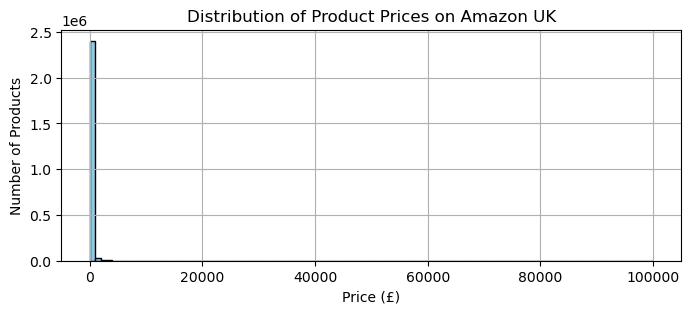

In [26]:
# 3

plt.figure(figsize=(8,3))
df['price'].hist(bins=100, color='skyblue', edgecolor='black')
plt.title("Distribution of Product Prices on Amazon UK")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")
plt.show()

In [ ]:
# There is a long tail: a few luxury items at very high prices stretch the x-axis, making the cheaper products squish together.

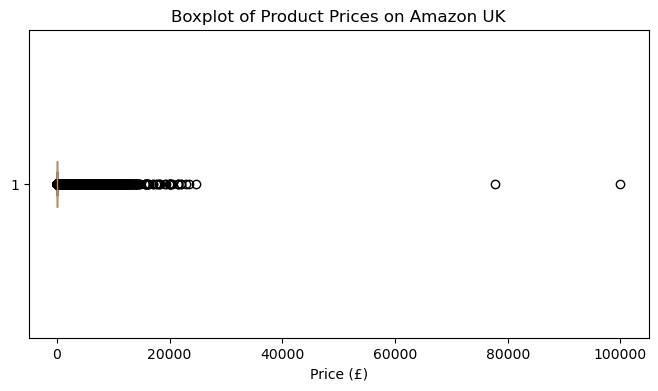

In [27]:
plt.figure(figsize=(8,4))
plt.boxplot(df['price'], vert=False, patch_artist=True, boxprops=dict(facecolor="lightgreen"))
plt.title("Boxplot of Product Prices on Amazon UK")
plt.xlabel("Price (£)")
plt.show()

In [29]:
# PART 3 : Unpacking Product Ratings
# 1

ratings = df["stars"].dropna()

mean_rating = ratings.mean()

median_rating = ratings.median()

mode_rating = ratings.mode()[0]

print(f"Mean rating: {mean_rating:.2f}")
print(f"Median rating: {median_rating:.2f}")
print(f"Mode rating: {mode_rating:.2f}")

Mean rating: 2.15
Median rating: 0.00
Mode rating: 0.00


In [ ]:
# There is a lot of 0.0 of stars, so the customers do not put stars. 

In [34]:
# 2

stars_note = df["stars"].dropna()

variance = stars_note.var()

std_dev = stars_note.std()

stars_note_range = stars_note.max() - stars_note.min()


Q1 = stars_note.quantile(0.25)
Q3 = stars_note.quantile(0.75)
IQR = Q3 - Q1

print(f"Variance: {variance:.2f}")
print(f"Standard Deviation: {std_dev:.2f}")
print(f"Range: {price_range:.2f}")
print(f"IQR: {IQR:.2f}")


Variance: 4.82
Standard Deviation: 2.19
Range: 100000.00
IQR: 4.40


In [36]:
# 3

from scipy.stats import skew, kurtosis

ratings = df["stars"].dropna()

# Skewness
skewness = skew(ratings)

# Kurtosis (Fisher’s definition → normal = 0)
kurt = kurtosis(ratings)

print(f"Skewness: {skewness:.2f}")
print(f"Kurtosis: {kurt:.2f}")


Skewness: 0.08
Kurtosis: -1.93


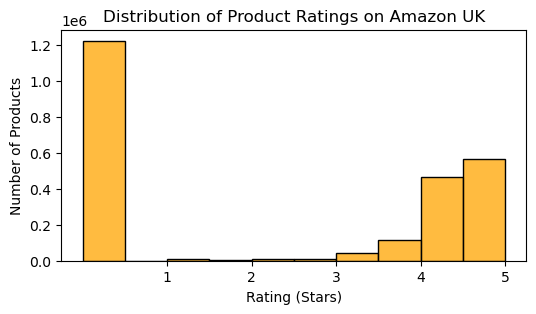

In [41]:
# 4 

import seaborn as sns

ratings = df["stars"].dropna()

plt.figure(figsize=(6,3))
sns.histplot(ratings, bins=10, kde=False, color='orange', edgecolor='black')
plt.title("Distribution of Product Ratings on Amazon UK")
plt.xlabel("Rating (Stars)")
plt.ylabel("Number of Products")
plt.xticks([1,2,3,4,5])
plt.show()
